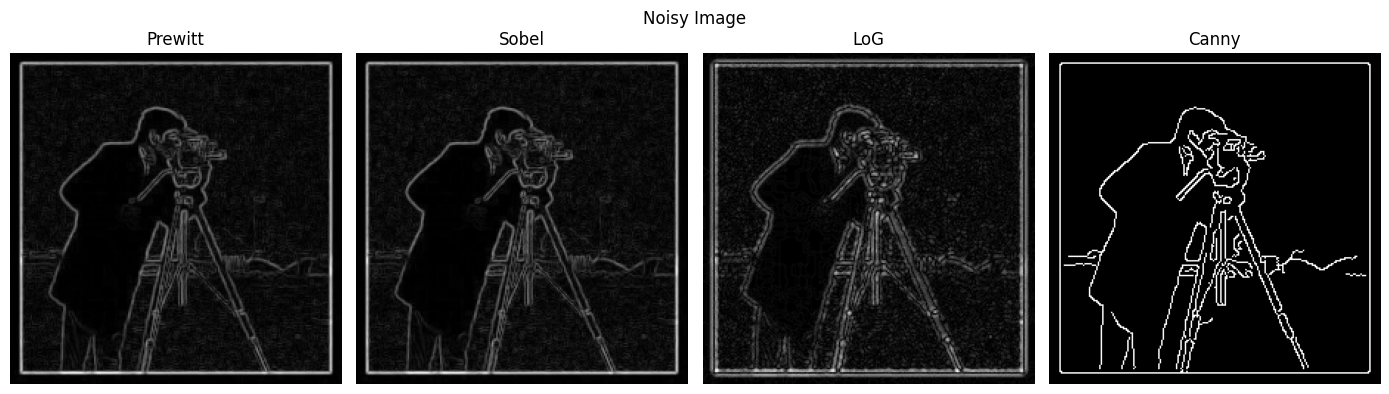


Noisy Image
Prewitt  | Edge Ratio: 0.9181 | Variance: 944.50
Sobel    | Edge Ratio: 0.9225 | Variance: 955.42
LoG      | Edge Ratio: 0.8465 | Variance: 1044.44
Canny    | Edge Ratio: 0.0590 | Variance: 3611.40


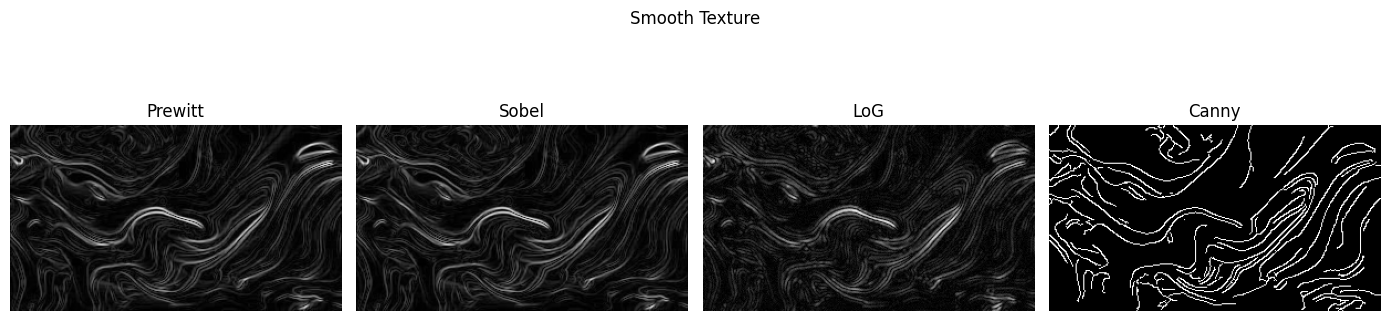


Smooth Texture
Prewitt  | Edge Ratio: 0.9930 | Variance: 730.16
Sobel    | Edge Ratio: 0.9927 | Variance: 747.27
LoG      | Edge Ratio: 0.9211 | Variance: 643.99
Canny    | Edge Ratio: 0.1058 | Variance: 6149.42


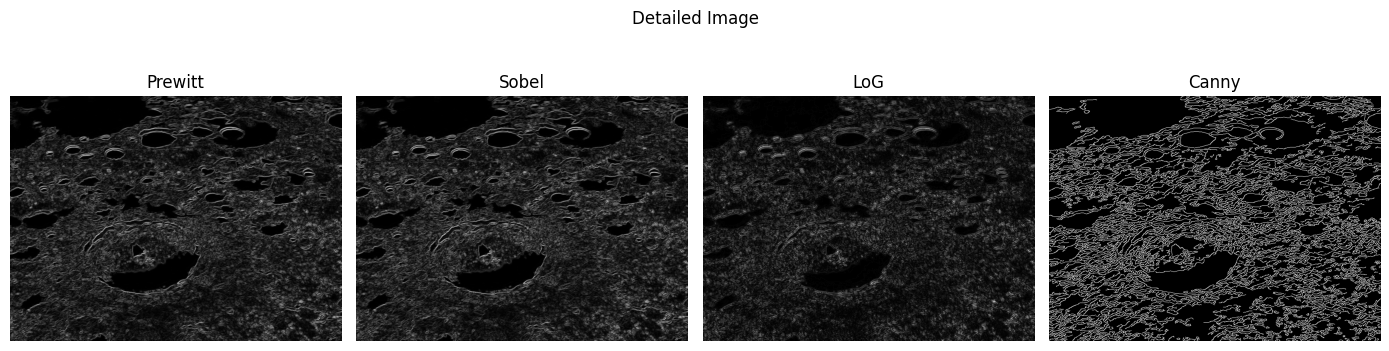


Detailed Image
Prewitt  | Edge Ratio: 0.9276 | Variance: 893.83
Sobel    | Edge Ratio: 0.9268 | Variance: 933.99
LoG      | Edge Ratio: 0.8849 | Variance: 606.04
Canny    | Edge Ratio: 0.1680 | Variance: 9089.50


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def prewitt_kernel(img):
    kx = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=np.float32)

    ky = np.array([[-1, -1, -1],
                   [ 0,  0,  0],
                   [ 1,  1,  1]], dtype=np.float32)

    gx = cv2.filter2D(img, cv2.CV_64F, kx)
    gy = cv2.filter2D(img, cv2.CV_64F, ky)

    mag = np.sqrt(gx**2 + gy**2)
    mag = 255 * mag / mag.max()

    return np.uint8(mag)

def sobel_kernel(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

    mag = np.sqrt(gx**2 + gy**2)
    mag = 255 * mag / mag.max()

    return np.uint8(mag)

def laplacian_of_gaussian_edge(img, sigma=1.2):
    blur = cv2.GaussianBlur(img, (5, 5), sigma)

    lap = cv2.Laplacian(blur, cv2.CV_64F)
    lap = np.abs(lap)
    lap = 255 * lap / lap.max()

    return np.uint8(lap)

def canny_edge(img, sigma=1.2):
    blur = cv2.GaussianBlur(img, (5, 5), sigma)
    return cv2.Canny(blur, 50, 150)

def edge_ratio(edge_img):
    return np.sum(edge_img > 0) / edge_img.size


def edge_variance(edge_img):
    return np.var(edge_img)

image_paths = {
    "Noisy Image": "high_noise.jpg",
    "Smooth Texture": "smooth_texture.jpg",
    "Detailed Image": "detailed.jpg"
}


for name, path in image_paths.items():
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    prewitt = prewitt_kernel(img)
    sobel = sobel_kernel(img)
    log = laplacian_of_gaussian_edge(img)
    canny = canny_edge(img)

    methods = {
        "Prewitt": prewitt,
        "Sobel": sobel,
        "LoG": log,
        "Canny": canny
    }

    plt.figure(figsize=(14, 4))
    for i, (title, result) in enumerate(methods.items()):
        plt.subplot(1, 4, i + 1)
        plt.imshow(result, cmap='gray')
        plt.title(title)
        plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

    print(f"\n{name}")
    for m, res in methods.items():
        print(f"{m:8s} | Edge Ratio: {edge_ratio(res):.4f} | Variance: {edge_variance(res):.2f}")